**Universidad Internacional de La Rioja (UNIR) - Máster Universitario en Inteligencia Artificial - Procesamiento del Lenguaje Natural** 

***
Datos del alumno (Nombre y Apellidos): <span style="color: yellow"> **NICOLÁS GUALTEROS PÉREZ** </span>

Fecha: <span style="color: yellow"> **21/04/2025** </span>
***

<span style="font-size: 20pt; font-weight: bold; color: #0098cd;">Trabajo: Named-Entity Recognition</span>

**Objetivos** 

Con esta actividad se tratará de que el alumno se familiarice con el manejo de la librería spacy, así como con los conceptos básicos de manejo de las técnicas NER

**Descripción**

En esta actividad debes procesar de forma automática un texto en lenguaje natural para detectar características básicas en el mismo, y para identificar y etiquetar las ocurrencias de conceptos como localización, moneda, empresas, etc.

En la primera parte del ejercicio se proporciona un código fuente a través del cual se lee un archivo de texto y se realiza un preprocesado del mismo. En esta parte el alumno tan sólo debe ejecutar y entender el código proporcionado.

En la segunda parte del ejercicio se plantean una serie de preguntas que deben ser respondidas por el alumno. Cada pregunta deberá responderse con un fragmento de código fuente que esté acompañado de la explicación correspondiente. Para elaborar el código solicitado, el alumno deberá visitar la documentación de la librería spacy, cuyos enlaces se proporcionarán donde corresponda.

# Parte 1: carga y preprocesamiento del texto a analizar

Observa las diferentes librerías que se están importando.

<span style="color: yellow"> **NOTA: Se agregan las librerías:** </span>

<span style="color: yellow"> Counter de Collections -> Counter permite contar los elementos de una lista facilmente, servirá para cuantificar rápidamente cuántas veces aparece cada tipo de entidad.</span>

<span style="color: yellow">matplotlib -> Librería para crear gráficos con los datos. Sirve para visualizar distribuciones, como un histograma de frecuencias de entidades (que se usarán durante el desarrollo de la actividad, en algunos puntos)</span>

<span style="color: yellow">time -> Librería time, para medir el tiempo de ejecución. Coon esta función se cronometra cada paso y se compara el rendimiento antes y después de ajustes en el preprocesamiento</span>

In [2]:
import pathlib
import spacy
import pandas as pd
from spacy import displacy
import csv
import es_core_news_md
# librerias adicionales
from collections import Counter
import matplotlib.pyplot as plt
import time

El siguiente código simplemente carga y preprocesa el texto. Para ello, lo primero que hace es cargar un modelo de lenguaje previamente entrenado. En este caso, se utiliza <i>es_core_news_md</i>: 

https://spacy.io/models/es#es_core_news_md


In [3]:
nlp = es_core_news_md.load()

El objeto <i>nlp</i> permite utilizar el modelo de lenguaje cargado, de forma que se puede procesar un texto y obtenerlo en su versión preprocesada. Así, nos permite realizar las diferentes tareas. En este caso, vamos a utilizar el pipeline para hacer un preprocesamiento básico, que consiste en tokenizar el texto.

<span style="color: yellow"> NOTA: 
para la lectura del archivo se hizo la prueba con latin1 y utf-8, se utilizó ***latin1*** porque leía mejor algunos caracteres del corpus y causó menos errores, por el tipo de datos del texto. </span>

In [4]:
filename = "./02Dataset_sin_procesar.csv" # asigna ruta del archivo 
lines_number = 100000 # numero de lineas(registros) a tomar en cuenta
data = pd.read_csv(filename, delimiter=';', encoding='latin1',nrows=lines_number,low_memory=False) # se carga el archivo con sus parámetros
data = data.dropna(subset=['CONTENIDO A ANALIZAR']) # Eliminar filas donde 'CONTENIDO A ANALIZAR'(Comentario) sea NaN o nulo
data = data.reset_index(drop=True) # Reinicia los indices de cada registro porque se eliminaron los nulos
#data = pd.read_csv(filename, delimiter=';',nrows=lines_number)
print(data.columns) # validacion de que la lectura del archivo es exitoso

Index(['ï»¿MEDIO', 'SOPORTE', 'URL', 'TIPO DE MENSAJE', 'CONTENIDO A ANALIZAR',
       'INTENSIDAD', 'TIPO DE ODIO', 'TONO HUMORISTICO', 'MODIFICADOR',
       'Unnamed: 9', 'Unnamed: 10', 'Unnamed: 11', 'Unnamed: 12',
       'Unnamed: 13', 'Unnamed: 14', 'Unnamed: 15'],
      dtype='object')


El código anterior carga el archivo CSV (opcionalmente con un límite de líneas a leer) y genera la variable <i>data</i>, que contiene un Dataframe (https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html) con los datos leídos del CSV.

Te vendrá bien conocer la siguiente documentación:
<ul>
    <li>https://spacy.io/api/doc</li>
    <li>https://spacy.io/api/token</li>
    <li>https://spacy.io/api/morphology#morphanalysis</li>
</ul>

### Playground

Utiliza este espacio para hacer pruebas y ensayos con las variables generadas con el código previo. A modo de ejemplo, se ofrece código que realiza las siguientes tareas: 


- leer un número dado de líneas del Dataframe y generar dos listas con los valores (se pueden leer directamente del DataFrame, se muestra el ejemplo como una opción más)
- procesar el texto de cada comentario


Para procesarlo, hay utilizar el objeto <i>nlp</i> y así obtener objetos de la clase <i>Doc</i> (https://spacy.io/api/doc)

Visita la documentación de dicha clase y experimenta probando las diferentes funciones y atributos 

In [5]:
# Puedes insertar aquí código de pruebas para experimentar con las diferentes funciones y atributos de 'doc'.
#print(data["CONTENIDO A ANALIZAR"][1])
#print(data["INTENSIDAD"][1])
lines_number = 100
doc = []
value = []

#con el bucle, generamos sendas listas con los comentarios ya parseados y con el valor de intensidad
for i in range(0, lines_number):
    
    #en un primer paso se parsea el comentario. En el segundo paso se añade el objeto a la lista
    tmp_doc = nlp(data["CONTENIDO A ANALIZAR"][i])
    doc.append(tmp_doc)
    
    #en un primer paso extrae el valor. En el segundo paso se añade el valor a la lista
    tmp_value = data["INTENSIDAD"][i]
    value.append(tmp_value)


#ejemplo de cómo recorrer un comentario palabra por palabra    
for token in doc[0]:
    print(token)

el
barÃÂ§a
nunca
acaeza
ante
un
segundo
b
ni
ante
un
tercera
,
ya
estan
los
arbitros
para
impedirlo
....
lo
de
messi
es
una
autentica
vergÃÂ¼enza


<span style="font-size: 20pt; font-weight: bold; color: #ffc77f;">Consideraciones a tener del código:</span>

- Todas las variables están nombradas con un guion bajo "_" seguido del número de la pregunta, con el fin de evitar confusiones entre variables similares.
- En cada proceso se utilizó la función ***time()*** para medir el tiempo de ejecución. Esto permitió identificar cuánto tarda cada proceso y así determinar una cantidad adecuada de registros a procesar.
- Tras el análisis, se decidió trabajar con **100.000** registros, considerando el equilibrio entre rendimiento y tiempo de ejecución en el entorno del notebook. Esta cantidad permite obtener resultados representativos y estimar el comportamiento si se procesara la totalidad de los datos.
- El corpus tuvo una "limpieza", eliminé las filas que tienen null en la variable ***CONTENIDO A ANALIZAR*** y reorganicé el index de los sobrantes para no tener problemas en la posterior lectura del archivo.

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 1.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">¿Cuántos registros contiene el corpus?</span>

In [4]:
# Incluye aquí el código generado para poder responder a tu pregunta
start_1 = time.time() # variable guarda tiempo actual (inicio)
data_completa = pd.read_csv(filename, delimiter=';', encoding='latin1', low_memory=False) # se asigna variable que contiene la información del archivo
num_registros = len(data_completa[["CONTENIDO A ANALIZAR", "INTENSIDAD"]].dropna()) # se asigna a la variable la longitud del archivo eliminando las nul
print("El corpus contiene ", str(num_registros), " registros.") # se imprime el mensaje con la variable que tiene el número de registros
end_1 = time.time() # variable guarda tiempo final
print("\n El tiempo que se demoró el proceso fue:" , round((end_1-start_1), 2) , "segundos") # se imprime los segundos que toma el proceso

El corpus contiene  574632  registros.

 El tiempo que se demoró el proceso fue: 5.38 segundos


In [7]:
data_completa = pd.read_csv(filename, delimiter=';', encoding='latin1', low_memory=False) # se asigna variable que contiene la información del archivo
cantidad_registros = data_completa.shape[0] 
print("El corpus contiene ", str(num_registros), " registros.") # se imprime el mensaje con la variable que tiene el número de registros

El corpus contiene  574632  registros.


<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>

 Pregunta 1: Para saber cuantos registros en total tiene el corpus
 
Primero se crea una variable **data_completa**  en donde uso la libreria *pandas* y su función *read_csv* para leer y cargar el archivo. Esta función lleva por parámetros: nombre/ubicacion del archivo, su delimitacion (en este caso por ;), la codificación de caracteres latin1 y low_memory=False para indicarle a pandas que no optimice memoria y pueda evitar errores duarnte la lectura de archivos grandes.

Luego, se crea una variable **num_registros** que guarda la longitud de los registros de las columnas ***CONTENIDO A ANALIZAR*** y ***INTENSIDAD***, luego se usa ***dropna()*** de pandas, para eliminar las filas vacias NaN y luego se usa len() para contar cuantas filas quedan luego de eliminar las vacías.
 
 Por último se usa *print()* para imprimir el mensaje con la variable que contiene el número total de registros.

**PDTA:** Quise hacerlo de dos formas diferentes, la segunda usando la función **shape** de pandas que encontré leyendo su documentación, se usa sobre la variable que tiene el archivo y se coloca[0] para indicarle que me traiga las filas de ese archivo.
Shape, Pandas, Python, tomado de "https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.shape.html"
 <hr>

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 2.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">¿Cuántas palabras totales hay en los comentarios del corpus?</span>

In [15]:
# Incluye aquí el código generado para poder responder a tu pregunta
start_2 = time.time() # variable guarda tiempo actual (inicio)
palabras_totales_2 = 0 # se crea una variable para que lleve el conteo de las palabras

for i in range(len(data)): # un for que recorre la cantidad de registros que tiene la variable data
    doc = nlp(data["CONTENIDO A ANALIZAR"][i]) # se asigna a la variable 'doc' la frase(comentario) tokenizada usando nlp

    lista_palabras_2 = [] # se crea una lista para guardar las palabras
    for token in doc: # un for que recorre cada token(palabra)
        if token.is_alpha: # un if para evaluar si el token(palabra) es alfabético
            lista_palabras_2.append(token) # si es alfabético se agrega el token a la lista (lista_palabras)
    palabras_totales_2 += len(lista_palabras_2) # a la variable del conteo se le agrega el número de tokens(palabras) de ese registro

# Imprimir el total de palabras
print("El corpus contiene ", palabras_totales_2, " palabras.") # se imprime el mensaje con la variable que tiene la cantidad de palabras

end_2 = time.time() # variable guarda tiempo final
print("\n El tiempo que se demoró el proceso fue: " , round((end_2-start_2)/60, 2) , "minutos.") # se imprime los segundos que toma el proceso

El corpus contiene  10114889  palabras.

 El tiempo que se demoró el proceso fue:  43.36 minutos.


<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>

 Pregunta 2: Para saber cuantas palabras hay en el corpus. 
 
Primero se crea una variable ***palabras_totales_2*** inicializada en 0 que llevará la cuenta de palabras, luego un for que recorre cada uno de los registros de ***data***, se le asigna a la variable ***doc*** el registro tokenizado usando la función **nlp** de la librería Spacy, siguiente se crea una lista ***lista_palabras_2*** para guardar las palabras alfabéticas del registro actual, Un for que recorre cada uno de los tokens(palabras) del registro y un if que valida si el token(palabra) es alfabético, en caso de que sí se agrega a la lista ***lista_palabras_2***, el número de tokens(palabras) del registro se suman a la variable ***palabras_totales_2***.

 Por último se usa la función **print** para mostrar el mensaje con la variable que tiene el número de palabras
 <hr>
 
  **Análisis:**
El número de palabras es elevado en general, esto puede ser por:
 - Los usuarios tienen a expresarse con profundidad, sumando una carga emocional por algun suceso, provocando largos textos en los comentarios.
 - Los usuarios prefieren explicar de manera detallada su opinión para dejar un mensaje claro, haciendo largo el comentario.
 - Son comentarios reales, ya que los bots suelen usar expresiones cortas y directas (menos palabras).

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 3.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">¿Cuál el número promedio de palabras en cada comentario?</span>

In [17]:
# Incluye aquí el código generado para poder responder a tu pregunta
start_3 = time.time() # variable guarda tiempo actual (inicio)
palabras_totales_3 = 0 # se crea una variable para que lleve el conteo de las palabras

for i in range(len(data)): # un for que recorre la cantidad de registros que tiene la variable data
    doc = nlp(data["CONTENIDO A ANALIZAR"][i]) # se asigna a la variable 'doc' la frase(comentario) tokenizada usando nlp
    lista_palabras_3 = [] # se crea una lista para guardar cantidad de palabras de ese registro
    for token in doc: # un for que recorre cada token(palabra)
        if token.is_alpha: # un if para evaluar si el token(palabra) es alfabético
            lista_palabras_3.append(token) # si es alfabético se agrega a la lista (lista_palabras)
    palabras_totales_3 += len(lista_palabras_3) # a la variable del conteo se le agrega el número de tokens(palabras) de ese registro

# variable 'promedio' que se calcula la suma de todas las palabras, dividido el número total de registros(data) 
promedio_3 = palabras_totales_3/len(data) 

# se imprime el mensaje con el promedio de palabras por cada comentario
print("El número promedio de palabras en cada comentario es: ", str(promedio_3)) 

end_3 = time.time() # variable guarda tiempo final
print("\n El tiempo que se demoró el proceso fue: " , round((end_3-start_3)/60, 2) , "minutos") # se imprime los segundos que toma el proceso

El número promedio de palabras en cada comentario es:  101.16507641222596

 El tiempo que se demoró el proceso fue:  43.65 minutos


<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>

**Pregunta 3:** Para saber el número promedio de palabras por comentario.
 
Se crea una variable ***palabras_totales_3*** inicializada en 0 que llevará la cuenta de palabras, Se usa un for que recorre cada uno de los registros de ***data***, se le asigna a la variable ***doc*** el registro tokenizado usando la función **nlp** de la librería Spacy, se crea una lista ***lista_palabras_3*** para guardar las palabras alfabéticas del registro actual, luego un for que recorre cada uno de los tokens(palabras) del registro, Un if que valida si el token(palabra) es alfabético, en caso de que sí se agrega a la lista ***lista_palabras_3***, el número de tokens(palabras) del registro se suman a la variable ***palabras_totales_3***. Por último se asigna una variable que tiene el promedio calculado con el número total de palabras sobre el numero de registros.

 Por último se usa la función **print** para mostrar el mensaje con la variable que tiene el promedio de palabras por comentario.
 <hr>
 
 **Análisis:**
 - El promedio de palabras por comentario es alto, lo que significa que los usuarios tienden a escribir textos largos, se toman el tiempo para hacerlo.
 - Otra cosa puede ser que los usuarios estén cargados emocionalmente y por eso escriben más para expresar sus emociones.
 - Los usuarios prefieren explicar su opinión de manera detallada para dejar un mensaje claro, y por eso los comentarios son largos.
 - Promedio de 101 palabras significa que los usuarios mínimo escriben 5 frases por comentario, en promedio, lo cual es bastante.

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 4.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Considerando dos grupos de comentarios (odio y no odio) ¿Cuál el número promedio de palabras en los comentarios de cada grupo?</span>

In [18]:
# Incluye aquí el código generado para poder responder a tu pregunta
start_4 = time.time() # variable guarda tiempo actual (inicio)
num_filas_odio_4 = 0 # creo una variable que llevará el conteo del número de filas con comentarios de odio
num_filas_no_odio_4 = 0 # creo una variable que llevará el conteo del número de filas con comentarios de NO odio
lista_odio_4 = [] # creo una lista donde se guardarán todas las palabras de los comentarios de odio
lista_no_odio_4 = [] # creo una lista donde se guardarán todas las palabras de los comentarios de NO odio


for i in range(len(data)): # un for que recorre la cantidad de registros que tiene la variable data
    if data["INTENSIDAD"][i] > 0: # if que valida si el comentario es de odio (Si la intensidad es mayor a 0, es decir es considerado odio)
        comentario_odio_4 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'comentario_odio' se guarda la frase(comentario) tokenizada con nlp
        num_filas_odio_4 += 1 # se suma 1 al contador de filas de odio
        for token in comentario_odio_4: # un for que recorre cada una de las palabras del comentario (odio)
             if token.is_alpha: # un if para evaluar si el token es alfabético
                 lista_odio_4.append(token) # si es alfabético se agrega a la lista de palabras de odio
    elif data["INTENSIDAD"][i] == 0: # if que valida si el comentario NO es de odio (Si la intensidad es igual a 0, es decir NO es considerado odio)
        comentario_no_odio_4 = nlp(data["CONTENIDO A ANALIZAR"][i])# en la varible 'comentario_no_odio' se guarda la frase(comentario) tokenizada con nlp
        num_filas_no_odio_4 += 1 # se suma 1 al contador de filas de NO odio
        for token in comentario_no_odio_4: # un for que recorre cada una de las palabras del comentario (NO opdio)
             if token.is_alpha: # un if para evaluar si el token es alfabético
                 lista_no_odio_4.append(token) # si es alfabético se agrega a la lista de palabras de NO odio

# en las variables se guarda el promedio de las palabras de odio y NO odio x comentario
promedio_odio_4 = len(lista_odio_4)/num_filas_odio_4 
promedio_no_odio_4 = len(lista_no_odio_4)/num_filas_no_odio_4 

# se imprime el mensaje con el promedio de odio y NO odio
print("El promedio de palabras por regsitros de odio es: " , round(promedio_odio_4, 2)) 
print("El promedio de palabras por registros de NO odio es: " , round(promedio_no_odio_4, 2)) 

end_4 = time.time() # variable guarda tiempo final
print("\n El tiempo que se demoró el proceso fue: " , round((end_4-start_4)/60, 0) , "minutos") # se imprime los segundos que toma el proceso

El promedio de palabras por regsitros de odio es:  14.13
El promedio de palabras por registros de NO odio es:  102.59

 El tiempo que se demoró el proceso fue:  45.0 minutos


<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>

**Pregunta 4:** Para saber el promedio de palabras por comentarios de odio y NO odio.

Se crean las variables ***num_filas_odio_4***,***num_filas_no_odio_4*** para llevar el conteo de filas de odio y NO odio respectivamente,luego se crean las variables ***lista_odio_4***,***lista_no_odio_4*** para guardar las palabras de los comentario de odio y NO odio respectivamente,siguiente se usa un **for** para recorrer la cantidad de registros de **data** y un **if** que valida si el comentario es de odio o no ( >0 odio,=0 NO odio), si es de odio en la vairable ***comentario_odio_4*** se guardan todas las palabras(tokens) del comentario y en ***num_filas_odio_4*** se suma 1 al contador de las filas de odio, con un **for** se recorre cada una de las palabras y se pregunta con un if, si es alfabético con la función **is_alpha()** de python, si es alfabético se agrega a la lista ***lista_odio_4*** quen contiene las palabras de odio. 

En caso de que NO sea considerado como odio ( ==0 ) entre al *elif*, y hace el mismo procedimiento anterior pero con las variables de NO Odio. Entonces, se asigna a la variable *comentario_no_odio_4* se le asigna el comentario tokenizado, luego se suma 1 al contador de registros con comentarios de NO odio, después un for que recorre cada letra del comentario y un if para validar si la palabra es alfabética usando la función **is_alpha()**, luego agredando la palabra a la lista.

Por último se imprime el mensaje con el promedio de odio y NO odio llamando las variables anteriores calculadas.
<hr>

**Análisis:**
El promedio de los comentarios de NO Odio es mas alto que el de los comentarios de odio (102 vs 14). Aunque suponía que los comentarios considerados Odio iban a tener mayor promedio de palabras, lo cual me sorprendió. Por lo cual podría suponer que:

- Los usuarios que no expresan odio tienden a extenderse más, quizá para argumentar, matizar o compartir experiencias.
- Los mensajes de odio a menudo buscan descarga rápida de emociones, usando frases cortas y directas.
- En las redes sociales e internet donde valoran la discusión entre personas, los participantes se esfuerzan en dar explicaciones completas para mantener su reputación y evitar malentendidos.
- Los usuarios que expresan su opinión sin necesidad de usar palabras que se consideran odio, tienden a extenderse para argumentar bien su punto de vista.

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 5.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Considerando dos grupos de comentarios (odio y no odio) ¿Cuál es el número promedio de oraciones en los comentarios de cada grupo?</span>

In [19]:
# Incluye aquí el código generado para poder responder a tu pregunta
start_5 = time.time() # variable guarda tiempo actual (inicio)
lista_odio_5 = [] # creo una lista donde se guardarán todas las oraciones de los comentarios de odio
lista_no_odio_5 = [] # creo una lista donde se guardarán todas las oraciones  de los comentarios de NO odio
num_registros_odio_5 = 0 # creo una lista que lleva el conteo de comentarios de odio
num_registros_no_odio_5 = 0 # creo una lista que lleva el conteo de comentarios de NO odio

for i in range(len(data)): # un for que recorre la cantidad de registros que tiene la variable data
    if data["INTENSIDAD"][i] > 0: # if que valida si el comentario es de odio (Si la intensidad es mayor a 0, es decir es considerado odio)
        num_registros_odio_5 += 1 # más 1 al contador de registros de odio
        oracion_odio_5 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'oracion_odio_5' se guarda la frase(comentario)
        for oracion_5 in oracion_odio_5.sents: # for para recorrer cada oracion del comentario .sents() de Spacy
            lista_odio_5.append(oracion_5) # se agrega la oracion a la lista de odio
    elif data["INTENSIDAD"][i] == 0: # if que valida si el comentario NO es de odio (Si la intensidad es igual a 0, es decir NO es considerado odio)
        num_registros_no_odio_5 += 1 # más 1 al contador de registros de NO odio
        oracion_no_odio_5 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'comentario_no_odio' se guarda la frase(comentario)
        for oracion_no_5 in oracion_no_odio_5.sents: # for para recorrer cada oracion del comentario .sents() de Spacy
            lista_no_odio_5.append(oracion_no_5) # se agrega la oracion a la lista de NO odio

# variables para calcular promedio (#oraciones/#registros) de odio y NO odio
promedio_filas_odio_5 = len(lista_odio_5)/num_registros_odio_5
promedio_filas_no_odio_5 = len(lista_no_odio_5)/num_registros_no_odio_5

# se imprime el mensaje con el promedio de odio y NO odio
print("El promedio de oraciones por comentario en el grupo de odio es: " , round(promedio_filas_odio_5,2 )) 
print("El promedio de oraciones por comentario en el grupo de NO odio es: " , round(promedio_filas_no_odio_5, 2))

end_5 = time.time() # variable guarda tiempo final
print("\n El tiempo que se demoró el proceso fue: " , round((end_5-start_5)/60, 0) , "minutos") # se imprime los segundos que toma el proceso

El promedio de oraciones por comentario en el grupo de odio es:  1.54
El promedio de oraciones por comentario en el grupo de NO odio es:  3.82

 El tiempo que se demoró el proceso fue:  56.0 minutos


<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>

**Pregunta 5:** Para saber el promedio de oraciones comentario en los grupos de odio y NO odio.

Se crean las variables ***num_registros_odio_5***,***num_registros_no_odio_5*** para llevar el conteo de filas de odio y NO odio respectivamente, luego se crean las variables (listas) ***lista_odio_5***,***lista_no_odio_5*** para guardar las palabras de los comentarios de odio y NO odio respectivamente. Siguiente se usa un **for** para recorrer la cantidad de registros de **data** y un **if** que valida si el comentario es de odio o no ( >0 odio,=0 NO odio), si es de odio en la vairable ***oracion_odio_5*** se guardan todas las caracteristicas del comentario y en ***num_registros_odio_5*** se suma +1 al contador de filas de Odio, después un **for** recorrer las oraciones de cada comentario usando la función ***.sents*** de Spacy. Se agrega la oración a la lista ***lista_odio_5***

Si no es un comentario de Odio (==0) entonces entra al **elif** (comentario de NO odio) y hace lo mismo anterior pero con las variables de NO odio, es decir: guarda el nlp del comentario en la variable *oracion_no_odio_5*, suma +1 al contador de comentarios de NO Odio y luego se usa un for para recorrer las oraciones de cada comentario usando la función ***.sents*** de Spacy. Después, se agrega la oración a la lista ***lista_no_odio_5***

Finalmente se crean dos variables **promedio_odio_4** y **promedio_no_odio_4** para calcular el promedio (#palabras/#registros) de odio y NO odio.
Por último se imprime el mensaje con el promedio de odio y NO odio llamando las variables anteriores creadas. Se usa el *round()* para limitar las variable a 2.
<hr>

**Análisis:**
El promedio de oraciones por comentarios del grupo NO Odio es mayor que el de Odio (3.82 vs 1.54) respectivamente, con dichso promedios podríamos deducir que:
- Los usuarios desarrollan sus ideas, explican sus opiniones y hasta en ocasiones dan ejemplos. Haciendo que el comentario lleve multiples oraciones.
- Los comentarios largos NO suelen ser impulsivos, por el contrario son comentarios que expresan una idea y su desarrollo es largo.
- En los comentarios de NO odio se usan mas puntuaciones, conectores y palabras en general, agrandando el comentario.
- Si los comentarios son de bots suelen ser cortos y directos, lo cual nos dice que si son humanos que se toman el tiempo.

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 6.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Considerando dos grupos de comentarios (odio y no odio) ¿Cuál es el porcentaje de comentarios que contienen entidades NER en cada grupo?</span>

In [20]:
# Incluye aquí el código generado para poder responder a tu pregunta
start_6 = time.time() # variable guarda tiempo actual (inicio)
num_registros_odio_6 = 0 # creo una variable que lleva el conteo de comentarios de odio
num_registros_no_odio_6 = 0 # creo una variable que lleva el conteo de comentarios de NO odio
num_registros_NER_odio_6 = 0 # creo una variable que lleva el conteo de los comentarios de odio que tienen al menos 1 entidad NER
num_registros_NER_no_odio_6 = 0 # creo una variable que lleva el conteo de los comentarios de NOP odio que tienen al menos 1 entidad NER

for i in range(len(data)): # un for que recorre la cantidad de registros que tiene la variable data
    if data["INTENSIDAD"][i] > 0: # if que valida si el comentario es de odio (Si la intensidad es mayor a 0, es decir es considerado odio)
        num_registros_odio_6 += 1 # más 1 al contador de registros de odio
        oracion_odio_6 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'oracion_odio_6' se guarda la frase(comentario)
        if len(oracion_odio_6.ents) > 0: # if para validar si el comentario tiene al menos una entidad NER (Odio)
            num_registros_NER_odio_6 += 1 # más 1 al contador de registros de odio que tienen entidad NER
    elif data["INTENSIDAD"][i] == 0: # if que valida si el comentario NO es de odio (Si la intensidad es igual a 0, es decir NO es considerado odio)
        num_registros_no_odio_6 += 1 # más 1 al contador de registros de NO odio
        oracion_no_odio_6 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'oracion_no_odio_6' se guarda la frase(comentario)
        if len(oracion_no_odio_6.ents) > 0: # if para validar si el comentario tiene al menos una entidad NER (NO odio)
            num_registros_NER_no_odio_6 += 1 # más 1 al contador de registros de NO odio que tienen entidad NER

# en las variables se guarda el calculo de porcentaje (Comentarios NER/Comentarios total) en Odio y NO odio
porcentaje_odio_6 = (num_registros_NER_odio_6/num_registros_odio_6)*100
porcentaje_no_odio_6 = (num_registros_NER_no_odio_6/num_registros_no_odio_6)*100

# se imprime el mensaje con el procentaje Odio y NO odio
print("El procentaje de comentarios que contienen entidades NER en el grupo Odio es: ", round(porcentaje_odio_6, 2))
print("El procentaje de comentarios que contienen entidades NER en el grupo NO Odio es: ", round(porcentaje_no_odio_6, 2))

end_6 = time.time() # variable guarda tiempo final
print("\n El tiempo que se demoró el proceso fue:" , round((end_6-start_6)/60, 0) , "minutos") # se imprime los segundos que toma el proceso

El procentaje de comentarios que contienen entidades NER en el grupo Odio es:  41.48
El procentaje de comentarios que contienen entidades NER en el grupo NO Odio es:  64.69

 El tiempo que se demoró el proceso fue: 56.0 minutos


<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>

**Pregunta 6:**  Para conocer el porcentaje de comentarios que contienen entidades NER en los grupos de Odio y NO Odio.

Se crean dos variables ***num_registros_odio_6*** y ***num_registros_no_odio_6*** que llevaran el contador de registros de Odio y NO Odio respectivamente. Además se crean las variables ***num_registros_NER_odio_6*** y ***num_registros_NER_no_odio_6*** para llevar la cuenta de los comentarios que tienen entidades NER, tanto del grupo Odio como el de NO Odio. Luego se usa un for para recorrer los registros del dataset *data*, se usa un *if* para validar si es un comentario de Odio o NO Odio (>0 odio,=0 NO odio). En caso de que sea considerado como Odio sesuma el +1 a la variable ***num_registros_odio_6*** que lleva el número de registros de Odio. Se asigna a la variable ***oracion_odio_6*** las caracteristicas del comentario con nlp, luego se usa un *if* para validar si el comentario tiene entidades usando la funcion **.ents** de Spacy, en caso de tener se suma el +1 a la variable ***num_registros_NER_odio_6*** que lleva el conteo de los comentario con entidades NER del Odio.

Si NO es un comentario de odio (Intensidad==0), hace el mismo procedimiento anterior pero con las variables de NO Odio, esdecir: suma +1 al contador de la variable de registros de NO Odio, guarda en la variabel ***oracion_no_odio_6*** las caracteristicas del comentario, después se usa un *if* para validar si el comentario contiene entidades, en caso de que sí, se agrega +1 al contador de comentario que tienen entidades de NO Odio.

Finalmente se crean las variables que contienen el procentaje de comentarios que tienen entidades NER tanto en Odio como en NO Odio. Calculado #registrosOdioNER/registrosNOOdioNER y *100 para obtener el porcentaje.

Por último se imprime el mensaje con la variable que tiene el porcentaje, usando un *round()* para reducir los decimales (en este caso a 2).
<hr>

**Análisis:**
Teniendo en cuenta que las entidades NER son palabras que se identifican con etiquetas como Personas, organizaciones, Lugares, fechas, etc.
El porcentaje (respecto al total de registros) de comentarios que tienen entidades NER en los grupos Odio y NO Odio es mayor en el caso de 'NO Odio', sus comentarios tienen un porcentaje de 64.69%, mientras que el de Odio es de 41.48%, con estos resultados se puede evidenciar que:

- En los comentarios de NO Odio los usuarios tienen a mencionas mas personas, lugares, fechas o eventos. Incrementando la probabilidad de uso de entidades NER en los comentarios.
- Cuando una persona expresa odio NO suele dar contexto, suele ser mas directo y claro. Reduciendo el uso de entidades NER para estos casos de comentarios de Odio.
- Que un comentario cuente con entidades NER infiere a que el usaurio procura ser claro, desarrollar una idea e invitar a respuestas de otros usuarios.
- Cuando los usuarios estan cargados emocionalmente y expresan un comentario de Odio, en ocasiones prefieren no mencionar directamente a la marca, persona o lugar. Recortando el procentaje de comentario NER en ese grupo.

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 7.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Considerando dos grupos de comentarios (odio y no odio) ¿Cuál es el porcentaje de comentarios que contienen entidades NER de tipo PERSON en cada grupo?</span>

In [30]:
# Incluye aquí el código generado para poder responder a tu pregunta
start_7 = time.time() # variable guarda tiempo actual (inicio)
num_registros_odio_7 = 0 # creo una variable que lleva el conteo de comentarios de odio
num_registros_no_odio_7 = 0 # creo una variable que lleva el conteo de comentarios de NO odio
num_registros_NER_PER_odio_7 = 0 # creo una variable que lleva el conteo de los comentarios de odio que tienen al menos 1 entidad NER
num_registros_NER_PER_no_odio_7 = 0 # creo una variable que lleva el conteo de los comentarios de NOP odio que tienen al menos 1 entidad NER

for i in range(len(data)): # un for que recorre la cantidad de registros que tiene la variable data
    if data["INTENSIDAD"][i] > 0: # if que valida si el comentario es de odio (Si la intensidad es mayor a 0, es decir es considerado odio)
        num_registros_odio_7 += 1 # más 1 al contador de registros de odio
        oracion_odio_7 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'oracion_odio_7' se guarda la frase(comentario)
        for token_odio_7 in oracion_odio_7.ents: # se recorre cada entidad NER del token 
            if token_odio_7.label_ == "PER": # if sobre si el token es igual a 'PER' 
                num_registros_NER_PER_odio_7 += 1 # si es igual aumenta el contador de comentarios de odio con entidad PER
                break # break para que solo cuente 1 al encontrar un PER en el comentario
    elif data["INTENSIDAD"][i] == 0: # if que valida si el comentario NO es de odio (Si la intensidad es igual a 0, es decir NO es considerado odio)
        num_registros_no_odio_7 += 1 # más 1 al contador de registros de NO odio
        oracion_no_odio_7 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'oracion_no_odio_7' se guarda la frase(comentario)
        for token_no_odio_7 in oracion_no_odio_7.ents: # se recorre cada entidad NER del token
            if token_no_odio_7.label_ == "PER": # si es igual aumenta el contador de comentarios de odio con entidad NER
                num_registros_NER_PER_no_odio_7 += 1 # si es igual aumenta el contador de comentarios de NO odio con entidad PER
                break # break para que solo cuente 1 al encontrar un PER en el comentario

# Se guarda en una variable el porcentaje de OdioPER y NOodioPER
porcentaje_odio_PER_7 = (num_registros_NER_PER_odio_7/num_registros_odio_7)*100 
porcentaje_no_odio_PER_7 = (num_registros_NER_PER_no_odio_7/num_registros_no_odio_7)*100 
# Se imprimen los mensajes con las variables calculadas
print("El procentaje de comentarios que contienen entidades NER de tipo PER en el grupo Odio es: ", round(porcentaje_odio_PER_7, 2),"%")
print("El procentaje de comentarios que contienen entidades NER de tipo PER en el grupo NO Odio es: ", round(porcentaje_no_odio_PER_7, 2),"%")

end_7 = time.time() # variable guarda tiempo final
print("\n El tiempo que se demoró el proceso fue: " , round((end_7-start_7)/60, 0) , "minutos") # se imprime los segundos que toma el proceso

El procentaje de comentarios que contienen entidades NER de tipo PER en el grupo Odio es:  20.9 %
El procentaje de comentarios que contienen entidades NER de tipo PER en el grupo NO Odio es:  34.57 %

 El tiempo que se demoró el proceso fue:  52.0 minutos


<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>

**Pregunta 7:** Para determinar rl porcentaje de comentarios que contienen al menos una entidad NER de tipo ***'PER'*** en cada uno de los grupos de Odio y NO Odio.

Se crean las variables ***num_registros_odio_7*** y ***num_registros_no_odio_7*** que llevarán el conteo de comentarios en total de Odio y NO Odio. Además se crean las variables ***num_registros_NER_PER_odio_7*** y ***num_registros_NER_PER_no_odio_7*** que lleva el conteo de los comentarios que tienen al menos una entidad de tipo NER. Para ello se usa un *for* que recorre cada uno de los registro de *data*, se usa un if para validar si es un comentario de Odio o NO Odio (>0 odio,=0 NO odio). Si el comentario es considerado Odio se suma +1 al contador de registros de odio, luego se asigna a la variable ***oracion_odio_7*** las caracteristicas del comentario usando *nlp*, después un *for* para recorrer cada una de las entidades del comentario usando la funcion **.label_** de Spacy, que permite identificar el tipo de entidad. Un *if* para validar si la entidad es de tipo **NER** se agrega al contador de registros de comentarios con al menos una entidad de tipo PER. Se usa un *break* para detener el bucle cuando ya encuentre la coincidencia (Porque se requiere la cantidad de comentarios con al menos una entidad NER de tipo PER, mas NO cuantas entidades de tipo PER.

En caso de que el comentario NO sea considerado como odio (Intensidad == 0) entrará al *elif* y hará el mismo proceso pero con las variables de NO odio, es decir: en ***num_registros_no_odio_7*** se suma +1 al contador de registros de NO Odio, en la variable ***oracion_no_odio_7*** se guardan las caracteristicas del comentario usando *nlp*, un *for* para recorrer cada una de las entidades NER con **.ents**. Luego un if para validar si la entidad NER es de tipo *PER* y si es positivo, se suma +1 al contador de comentarios con entidad NER de PER en el grupo de NO Odio.

Finalmente se crean las variables que contendran el porcentaje de comentarios con entidades NER de tipo PER, tanto en el grupo de Odio como el de NO Odio, ***porcentaje_odio_PER_7*** y ***porcentaje_no_odio_PER_7***.

Por último se imprime el mensaje con las variables del porcentaje, se usa *round()* para redondear los decimales a 2 cifras.
<hr>

**Análisis:**
Teniendo en cuenta que las entidades NER son palabras que se identifican con etiquetas como Personas, organizaciones, Lugares, fechas, etc. Para este caso se calcula el porcentaje pero que sean de tipo PER = Persona.
En base a el resultado en donde indica que con 100.000 registros el porcentaje de comentarios con entidad NER de tipo *PER* del grupo NO Odio es del 34.57% y el de Odio de 20.9%. siendo mayor el del grupo de NO Odio, esto puede deberse a:

- Los comentarios considerados como NO Odio, tieneden a referirse a personas específicas, para mencionar figuras públicas, retratar a alguien, etc.
- Mientras que los comentarios de Odio, suelen evitar mencionar a personas directamente sino atacan grupos, organizaciones, equipos, empresas, etc. No a alguien es específico.
- Mencionar personas con nombre propio en un comentario suele estar vinculado a una conexión emocional o un deseo de relatar hechos personales.
- La baja cantidad de nombres *(PER)* en los comentario de Odio se debe a un posible postura de evasión, donde los usuarios evitan hacer acusaciones directos, pues reducen su exposición a sanciones o reproches, especialmente si es una red social.
- Este tipo de patrón puede ser relevante para entrenar modelos de detección o clasificación automática de odio, ya que la ausencia de entidades tipo *PER* podría ser un indicador de lenguaje más hostil, indicando Odio.

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 8.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Considerando dos grupos de comentarios (odio y no odio) ¿Cuál es el porcentaje de palabras en cada combinación posible de género y número (p.ej. masculino singular) en cada grupo?</span>

In [32]:
# Incluye aquí el código generado para poder responder a tu pregunta
start_8 = time.time() # variable guarda tiempo actual (inicio)

lista_palabras_odio_8 = [] # creo una lista donde se guardarán todas las palabras de los comentarios de odio
lista_palabras_no_odio_8 = [] # creo una lista donde se guardarán todas las palabras de los comentarios de NO odio
masculino_singular_odio_8 = 0 # contador de combinaciones ['Masc']['Sing'] en Odio
masculino_plural_odio_8 = 0 # contador de combinaciones ['Masc']['Plur'] en Odio
femenino_singular_odio_8 = 0 # contador de combinaciones ['Fem']['Sing'] en Odio
femenino_plural_odio_8 = 0 # contador de combinaciones ['Fem']['Plur'] en Odio
masculino_singular_no_odio_8 = 0 # contador de combinaciones ['Masc']['Sing'] en NO Odio
masculino_plural_no_odio_8 = 0 # contador de combinaciones ['Masc']['Plur'] en NO Odio
femenino_singular_no_odio_8 = 0 # contador de combinaciones ['Fem']['Sing'] en NO Odio
femenino_plural_no_odio_8 = 0 # contador de combinaciones ['Fem']['Plur'] en NO Odio

for i in range(len(data)): # un for que recorre la cantidad de registros que tiene la variable data
    if data["INTENSIDAD"][i] > 0: # if que valida si el comentario es de odio (Si la intensidad es mayor a 0, es decir es considerado odio)
        oracion_odio_8 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'oracion_odio_8' se guarda la frase(comentario)
        for token_odio_8 in oracion_odio_8: # for que recorre cada token(palabra) de la oracion
            genero_odio_8 = token_odio_8.morph.get("Gender") # se le asigna a la variable el Género
            num_gramatical_odio_8 = token_odio_8.morph.get("Number") # se le asigna a la variable el Número
            lista_palabras_odio_8.append(token_odio_8) # se agrega la plabara a la lista
            # ifs para saber a que combinacion pertenece la palabra, si pertenece se suma 1 al contador
            if "Masc" in genero_odio_8 and "Sing" in num_gramatical_odio_8:
                masculino_singular_odio_8 += 1
            elif "Fem" in genero_odio_8 and "Sing" in num_gramatical_odio_8:
                femenino_singular_odio_8 += 1
            elif "Masc" in genero_odio_8 and "Plur" in num_gramatical_odio_8:
                masculino_plural_odio_8 += 1
            elif "Fem" in genero_odio_8 and "Plur" in num_gramatical_odio_8:
                femenino_plural_odio_8 += 1
    elif data["INTENSIDAD"][i] == 0: # if que valida si el comentario es de odio (Si la intensidad es mayor a 0, es decir es considerado odio)
        oracion_no_odio_8 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'oracion_no_odio_8' se guarda la frase(comentario)
        for token_no_odio_8 in oracion_no_odio_8: # for que recorre cada token(palabra) de la oracion
            genero_no_odio_8 = token_no_odio_8.morph.get("Gender") # se le asigna a la variable el Género
            num_gramatical_no_odio_8 = token_no_odio_8.morph.get("Number") # se le asigna a la variable el Número
            lista_palabras_no_odio_8.append(token_no_odio_8) # se agrega la plabara a la lista
            # ifs para saber a que combinacion pertenece la palabra, si pertenece se suma 1 al contador
            if "Masc" in genero_no_odio_8 and "Sing" in num_gramatical_no_odio_8:
                masculino_singular_no_odio_8 += 1
            elif "Fem" in genero_no_odio_8 and "Sing" in num_gramatical_no_odio_8:
                femenino_singular_no_odio_8 += 1
            elif "Masc" in genero_no_odio_8 and "Plur" in num_gramatical_no_odio_8:
                masculino_plural_no_odio_8 += 1
            elif "Fem" in genero_no_odio_8 and "Plur" in num_gramatical_no_odio_8:
                femenino_plural_no_odio_8 += 1

# variables % combinaciones en odio
porcentaje_odio_ms_8 = masculino_singular_odio_8/len(lista_palabras_odio_8)
porcentaje_odio_fs_8 = femenino_singular_odio_8/len(lista_palabras_odio_8)
porcentaje_odio_mp_8 = masculino_plural_odio_8/len(lista_palabras_odio_8)
porcentaje_odio_fp_8 = femenino_plural_odio_8/len(lista_palabras_odio_8)
# variables % combinaciones en NO odio
porcentaje_no_odio_ms_8 = masculino_singular_no_odio_8/len(lista_palabras_no_odio_8)
porcentaje_no_odio_fs_8 = femenino_singular_no_odio_8/len(lista_palabras_no_odio_8)
porcentaje_no_odio_mp_8 = masculino_plural_no_odio_8/len(lista_palabras_no_odio_8)
porcentaje_no_odio_fp_8 = femenino_plural_no_odio_8/len(lista_palabras_no_odio_8)
# Se imprime la tabla con los resultados
print("Los resultados de los porcentajes por combinacion(género y número) son: \n")
print("|| " , "Porcentaje masculino/singular en el grupo odio: " , round(porcentaje_odio_ms_8, 2) , " ||")
print("|| " , "Porcentaje femenino/singular en el grupo odio: " , round(porcentaje_odio_fs_8, 2) , " ||")
print("|| " , "Porcentaje masculino/plural en el grupo odio: " , round(porcentaje_odio_mp_8, 2) , " ||")
print("|| " , "Porcentaje femenino/plural en el grupo odio: " , round(porcentaje_odio_fp_8, 2) , " ||")
print("-------------------------------------------------------------------------------------------------")
print("|| " , "Porcentaje masculino/singular en el grupo NO odio: " , round(porcentaje_no_odio_ms_8, 2) , "||")
print("|| " , "Porcentaje femenino/singular en el grupo NO odio: " , round(porcentaje_no_odio_fs_8, 2) , " ||")
print("|| " , "Porcentaje masculino/plural en el grupo NO odio: " , round(porcentaje_no_odio_mp_8, 2) , " ||")
print("|| " , "Porcentaje femenino/plural en el grupo NO odio: " , round(porcentaje_no_odio_fp_8, 2) , " ||")

end_8 = time.time() # variable guarda tiempo final
print("\n El tiempo que se demoró el proceso fue: " , round((end_8-start_8)/60, 0) , "minutos") # se imprime los segundos que toma el proceso
#['Masc']     ['Sing']
#['Fem']     ['Plur']

Los resultados de los porcentajes por combinacion(género y número) son: 

||  Porcentaje masculino/singular en el grupo odio:  0.14  ||
||  Porcentaje femenino/singular en el grupo odio:  0.11  ||
||  Porcentaje masculino/plural en el grupo odio:  0.06  ||
||  Porcentaje femenino/plural en el grupo odio:  0.03  ||
-------------------------------------------------------------------------------------------------
||  Porcentaje masculino/singular en el grupo NO odio:  0.16 ||
||  Porcentaje femenino/singular en el grupo NO odio:  0.12  ||
||  Porcentaje masculino/plural en el grupo NO odio:  0.06  ||
||  Porcentaje femenino/plural en el grupo NO odio:  0.04  ||

 El tiempo que se demoró el proceso fue:  49.0 minutos


<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>

 **Pregunta 8:** Para conocer el porcentaje de palabras de las diferentes combinaciones posibles de género y número en cada uno de los grupos (Odio y NO Odio):
Se crean las listas ***lista_palabras_odio_8*** y ***lista_palabras_no_odio_8*** para guardar todas las palabras de los comentarios de los grupos Odio y NO Odio, también se crean 8 variables que llevarán el conteo de todas las posibles coombinaciones en ambos grupos (masculino_singular_odio_8, masculino_plural_odio_8, femenino_singular_odio_8, femenino_plural_odio_8, masculino_singular_no_odio_8, masculino_plural_no_odio_8, femenino_singular_no_odio_8, femenino_plural_no_odio_8).

Se usa un for para recorrer cada uno de los regsitros del corpus *data*, se usa un if para validar si es un comentario de Odio o NO Odio (>0 odio,=0 NO odio). Si el comentario es considerado Odio se guarda en la variable ***oracion_odio_8*** las caracteristicas del comentario. Luego un for para recorrer cada uno de los tokens(palabra), se crean las variables ***genero_odio_8*** y ***num_gramatical_odio_8*** para guardar el género y el número gramatical de la morfología de cada palabra del comentario. Luego se agrega la palabra a la lista ***lista_palabras_odio_8***. Luego hay 4 *if* anidados, validando a qué combinación pertenece la palabra *(masculino_singular_odio_8, femenino_singular_odio_8, masculino_plural_odio_8, femenino_plural_odio_8)*, cuando coincida con la combinación se suma el +1 al contador de esa combinación.

En caso de que el comentario NO sea considerado como Odio, se ejecutan las mismas instrucciones pero con las variables que corresponden a el grupo NO Odio, es decir: Se asigna el comentario a la varible ***oracion_no_odio_8*** usando *nlp*, un *for* para recorrer cada una de las palabras, luego se asignan a las variables ***num_gramatical_no_odio_8*** y ***genero_no_odio_8*** el género y el número gramatical de la morfología de cada palabra del comentario. Siguiente a esto se agrega la palabra a la lista de palabras del grupo NO Odio. Luego hay 4 *if* anidados, validando a qué combinación pertenece la palabra *(masculino_singular_no_odio_8, femenino_singular_no_odio_8, masculino_plural_no_odio_8, femenino_plural_no_odio_8)*, cuando coincida con la combinación se suma el +1 al contador de esa combinación.

Finalmente se crean las variables que guardaran el porcentaje de las combinacioes en ambos grupos Odio y NO Odio, numero de veces que existe la combinación / numero total de palabras del grupo, se usa el *len* para calcular el tamaño de la lista.

Por último, se imprime el mensaje con el porcentaje de las combinaciones de cada grupo, con las variables del porcentaje, se usa el *round()* para mostrar únicamente 2 decimales al porcentaje.
<hr>

**Análisis:**
Los resultados muestran que en el grupo de comentarios clasificados como No Odio, los porcentajes de todas las combinaciones de género y número gramatical (masculino/femenino, singular/plural) son ligeramente superiores en comparación con el grupo de Odio. Esto nos permite identificar:

- En ambos grupos (Odio y NO Odio) la combinación más frecuente es la de *'Masculino/Singular*, esto puede deberse que el lenguaje español esta gramaticalmente definido como masculino.
- La baja presencia de la combinación *femenino plural* y *masculino plural* puede indicar que los comentarios, tanto de odio como no odio, tienden a no dirigirse o referirse directamente a grupos o a personas femeninas en general.
- Aunque existen diferencias entre los grupos, estas no son muy marcadas. Esto sugiere que los comentarios, tanto de Odio como de No Odio, están dirigidos hacia personas de género masculino y femenino, sin una preferencia particular.
- También se podría afirmar que los comentarios son escritos tanto por personas femeninas como masculinas, provocando un uso de combinaciones de ambos géneros y logrando un porcentaje muy similar.
- Con este resultado, sería posible desarrollar un modelo de aprendizaje que utilice las combinaciones de palabras y entidades más frecuentes para clasificar un comentario como odio o no odio, basándose únicamente en las entidades de las palabras.

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 9.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Considerando dos grupos de comentarios (odio y no odio), indica cuántas entidades de cada tipo posible se reconocen en cada uno de los grupos</span>

In [33]:
# Incluye aquí el código generado para poder responder a tu pregunta
start_9 = time.time() # variable guarda tiempo actual (inicio)
contador_odio_9 = Counter() # se crea el contador de cada una de las entidades para el grupo de Odio
contador_no_odio_9 = Counter() # se crea el contador de cada una de las entidades para el grupo de NO Odio

for i in range(len(data)): # un for que recorre la cantidad de registros que tiene la variable data
    if data["INTENSIDAD"][i] > 0: # if que valida si el comentario es de odio (Si la intensidad es mayor a 0, es decir es considerado odio)
        oracion_odio_9 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'oracion_odio_9' se guarda la frase(comentario)
        for token_odio_9 in oracion_odio_9.ents: # for que recorre la entidad de cada una de las palabras de odio
            contador_odio_9[token_odio_9.label_] += 1 # se agrega la entidad al contador
    elif data["INTENSIDAD"][i] == 0: # if que valida si el comentario es de odio (Si la intensidad es mayor a 0, es decir es considerado odio)
        oracion_no_odio_9 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'oracion_no_odio_8' se guarda la frase(comentario)
        for token_no_odio_9 in oracion_no_odio_9.ents: # for que recorre la entidad de cada una de las palabras de NO Odio
            contador_no_odio_9[token_no_odio_9.label_] += 1 # se agrega la entidad al contador

# se imprime el mensaje de las entidades, la cantidad de veces que aparecen en el grupo de Odio y NO Odio
print("Las entidades y el número de veces que aparecen en el grupo de Odio son: " + str(contador_odio_9))
print("Las entidades y el número de veces que aparecen en el grupo de NO odio son: " + str(contador_no_odio_9))  

end_9 = time.time() # variable guarda tiempo final
print("\n El tiempo que se demoró el proceso fue: " , round((end_9-start_9)/60, 0) , "minutos") # se imprime los segundos que toma el proceso

Las entidades y el número de veces que aparecen en el grupo de Odio son: Counter({'PER': 481, 'MISC': 309, 'LOC': 268, 'ORG': 138})
Las entidades y el número de veces que aparecen en el grupo de NO odio son: Counter({'LOC': 157842, 'PER': 139168, 'MISC': 107632, 'ORG': 50367})

 El tiempo que se demoró el proceso fue:  52.0 minutos


<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>

***Pregunta 9:*** Para obtener las entidades y la cantidad de veces que aparecen en los comentario de cada uno de los grupos Odio y NO Odio:
En este punto se utiliza la función ***Counter()*** de la librería ***collection*** nativa de python, este *Counter()* sirve para contar elementos de una manera eficiente (en este caso contará cada una de las entidades y la cantidad de veces).

Se crean las variables ***contador_odio_9*** y ***contador_no_odio_9*** a las cuales se les asigna el contador con *Counter()*. Luego un *for* para recorrer los registros del corpues *data*, un if para validar si es un comentario de Odio o NO Odio (>0 odio,=0 NO odio). Si el comentario es considerado Odio, las caracteristicas del comentario se guarda en la variable ***oracion_odio_9*** usando *nlp*. Después se usa un *for* para recorrer las entidades de cada una de las palabras o tokens. Al contador creado previamente ***contador_odio_9*** se le agrega +1 al tipo de entidad.

Si NO es un comentario de Odio, entra al *elif* (Intensidad==0), se le asigna a la variable ***oracion_no_odio_9*** las caracteristicas del comentario, usando *nlp*. Se usa un *for* para recorrer cada entidad de las palabras del comentario y con la variable ***contador_no_odio_9*** se le suma +1 al contador de la entidad.

Finalmente se usa *print* para imprimir el mensaje con la variable(Contador) que tienen los tipos de entidades y las veces que aparecen. Se usa el *str()* para convertir a String el resultado del contador y se pueda imprimir.
<hr>

**Análisis:**
Teniendo en cuenta que las entidades NER son palabras que se identifican con etiquetas como Personas, organizaciones, Lugares, fechas, etc.
Los resultados muestran una diferencia abrumadora entre los grupos de Odio y NO Odio, en cuanto a la cantidad de entidades reconocidas NO ODIO cuenta con muchas más. Y esto podría deberse a:

- Los comentarios del grupo *NO Odio* son mucho más extensos, en promedio tienen más palabras y oraciones. Por lo que simplemente hay más texto disponible para obtener entidads NER.
- Los comentarios de *NO Odio* parecen ser más informativos, es decir, mencionan más personas, lugares, eventos, marcas, etc. Mientras que los comentarios de *Odio* pueden estar más centrados en insultos, opiniones o lenguaje ofensivo, que no siempre nombran a entidades específicas.
- Los comentarios de *NO Odio* suelen ser mas redactados, que cuenten con sujeto y complemento, aumentando la probabilidad de encontrar entidades NER. Los comentarios *Odio* son más informales e indirectos, sin entidades por identificar.

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 10.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Considerando dos grupos de comentarios (odio y no odio), extrae y muestra los 100 lemas más repetidos en los comentarios de cada grupo</span>

In [10]:
# Incluye aquí el código generado para poder responder a tu pregunta
start_10 = time.time() # variable guarda tiempo actual (inicio)
contador_odio_10 = Counter() # se crea el contador de cada una de las entidades para el grupo de Odio
contador_no_odio_10 = Counter() # se crea el contador de cada una de las entidades para el grupo de NO Odio

for i in range(len(data)): # un for que recorre la cantidad de registros que tiene la variable data
    if data["INTENSIDAD"][i] > 0: # if que valida si el comentario es de odio (Si la intensidad es mayor a 0, es decir es considerado odio)
        oracion_odio_10 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'oracion_odio_10' se guarda la frase(comentario)
        for token_odio_10 in oracion_odio_10: # for que recorre cada palabra del comentario
            contador_odio_10[token_odio_10.lemma_] += 1 # se agrega al contador de Odio el lema de la palabra y lo suma
    elif data["INTENSIDAD"][i] == 0: # if que valida si el comentario es de odio (Si la intensidad es mayor a 0, es decir es considerado odio)
        oracion_no_odio_10 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'oracion_no_odio_8' se guarda la frase(comentario)
        for token_no_odio_10 in oracion_no_odio_10:  # for que recorre cada palabra del comentario
            contador_no_odio_10[token_no_odio_10.lemma_] += 1 # se agrega al contador de NO Odio el lema de la palabra y lo suma

# variables que tienen el top 100 de los lemas en Odio y NO odio
top_100_lemas_odio = contador_odio_10.most_common(100) # se usa el most_common, funcion de Counter, para traer el 100 mas repetidos
top_100_lemas_no_odio = contador_no_odio_10.most_common(100)

# se imprime el mensaje con el top 100 de lemas para Odio y NO odio
print("Los 100 lemas que mas se repiten en el grupo de comentario de Odio son: \n" + str(top_100_lemas_odio) + "\n")
print("Los 100 lemas que mas se repiten en el grupo de comentario de NO Odio son: \n" + str(top_100_lemas_no_odio) + "\n")

end_10 = time.time() # variable guarda tiempo final
print("\n El tiempo que se demoró el proceso fue: " , round((end_10-start_10)/60, 0) , "minutos") # se imprime los segundos que toma el proceso

Los 100 lemas que mas se repiten en el grupo de comentario de Odio son: 
[('el', 1679), ('de', 1308), (',', 1292), ('.', 1060), ('que', 1045), ('él', 751), ('a', 662), ('y', 643), ('ser', 630), ('uno', 575), ('!', 493), ('no', 402), ('en', 399), ('©', 297), ('este', 256), ('?', 237), ('haber', 228), ('...', 213), ('por', 210), ('con', 187), ('del', 176), ('su', 165), ('para', 159), ('yo', 156), ('tener', 149), ('"', 144), ('si', 139), ('como', 139), ('mierda', 133), ('todo', 131), ('informativo', 120), ('ir', 118), ('mã\x83â¡s', 113), ('puta', 113), ('hacer', 108), ('ese', 104), ('pero', 102), ('¡', 101), ('tú', 97), ('sois', 96), ('o', 94), ('#', 92), ('al', 89), ('\r\n', 89), ('ya', 86), ('terrorismo', 84), ('asco', 78), ('hijo', 78), (' ', 77), ('poder', 67), ('decir', 67), ('basura', 65), ('ni', 64), ('dar', 63), ('otro', 62), ('mucho', 58), ('ver', 58), ('quã\x83â', 57), ('(', 55), (')', 55), ('....', 54), ('sin', 50), ('\xa0', 50), ('s', 49), ('tu', 49), ('menudo', 48), ('gente',

<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>

***Pregunta 10:*** Para extraer los 100 lemas más repetidos de cada uno de los grupos Odio y NO Odio. En este punto se utiliza la función ***Counter()*** de la librería ***collection*** nativa de python, este *Counter()* sirve para contar elementos de una manera eficiente (en este caso contará cada uno de los lemas de los comentarios y la cantidad de veces que aparecen).

Se crean las variables ***contador_odio_10*** y ***contador_no_odio_10*** a las cuales se les asigna el contador con *Counter()*. Luego se usa un *for* para recorrer los registros del corpus, siguiente un *if* para validar si es un comentario de Odio o NO Odio (>0 odio,=0 NO odio). Si el comentario es considerado Odio, las caracteristicas del comentario se guarda en la variable ***oracion_odio_10*** usando *nlp*. Luego se usa un *for* que recorre cada uno de los tokens del comentario. Ahora se agrega al contador ***contador_odio_10*** el +1 del lema identificado. Para obtener el lema usamos la función **.lemma_** de Spacy.

En caso de que NO sea un comentario considerado como NO Odio entra al *elif* (Intensidad==0), en la variable ***oracion_no_odio_10*** se guarda las caracteristicas del comentario, usando *nlp*. Luego se usa un for para recorrer cada uno de los token y se agrega +1 al contador el lema identificado. Para obtener el lema usamos la función **.lemma_** de Spacy.

Finalmente se les asignan los 100 lemas más repetidos usando la función *most_common* y como parámetro el número de lemas (en este caso 100) a las variables ***top_100_lemas_odio*** y ***top_100_lemas_no_odio***.

Por último con *print* se imprime el mensaje de los 100 lemas más repetidos por grupo (Odio y NO Odio), se tuliza el *str()* para convertir el contador en String y poder imprimirlo.
<hr>

**Análisis:**
Teniendo en cuenta que los lemas son la forma base de una palabras, es decir como vemos la palabra en su forma de diccionario. Teniendo en cuenta el top 100 de lemas que mas se repiten tanto en el grupo de *Odio* como el de *NO Odio*, los resultados obetnidos en general son que el grupo de comentarios de NO Odio tienen mayor cantidad de lemas en comparaciín al de Odio. Esto puede ocurrir por:

- Entre los 100 lemas mas frecuentes del grupo *Odio* aparecen: "mierda", "puta", "asco", "hijo", "basura", "tonto", "gentuza", "terrorismo", "terrorista", "panfleto", "puto". Demostrando que el grupo de *Odio* muestra lemas cargados emocionalmente y vocabulario violento y ofensivo.
- Los comentarios no odio tienen un lenguaje más neutro, rico y estructurado, lo que apunta a un estilo más informativo o conversacional.
- También se destacan lemas como "!", "¡", "...", "©", "#" y emoticonos están más presentes en *Odio*. Lo que reporesenta datos ruidosos en el corpues.
- Con estos resultados obtenidos sería posible crear un modelo predictivo de clasificación de comentarios como *"Odio"* y *"NO Odio"* basandose en sus lemas. utilizando NLP y aprendizaje automático.

<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">Pregunta 11.</span>
<span style="font-size: 14pt; font-weight: bold; color: #0098cd;">¿Es posible utilizar alguna de las características extraídas en las preguntas anteriores para determinar si un mensaje contiene odio? Justifica tu respuesta con el análisis estadístico que consideres necesario.</span>

<b>Incluye aquí, debajo de la línea, la explicación de tu respuesta</b>
<hr>

***Pregunta 11:*** 

### Gráfica 1 (Numero Palabras Por Comentario y Cantidad (Odio y NO Odio)

De las caracteristicas extraidas de las preguntas anteriores se puede determinar que en la mayoría de casos la longitud de los comentarios puede dar una idea sobre si el comentario es de *Odio* o *NO Odio*, pues la tendencia muestra que si un comentario es extenso, suele pertenecer al grupo de los NO Odio.
Para esto es posible realizar un histograma que muestre el número de palabras por comentario en cada uno de los grupos y pintarlos de un color diferente. En este caso *Numero Palabras Por Comentario y Cantidad (Odio y NO Odio)* muestra los valores del grupo *'odio'* de color azul y los de *'no odio'* de color rojo. 

El histograma representa que en los primeros registros los comentarios de *Odio* son más extensos respecto a palabras y oraciones. Pero luego desde el registro número 200 ***aproximadamente*** el grupo de *NO Odio* supera por mucho la longitud de los comentarios. solo hay algunos picos en los registros 1200 ***aproximadamente*** y 2300 ***aproximadamente***. Sin embargo, la tendencia general es comentarios más extensos en el grupo de *NO Odio* porque suelen ser comentarios que expresa una opinion, llevan carga emocional, etc. Mientras que los de *Odio* que son pocos, suele ser porque son comentarios directos y claros, con hostilidad.

<hr>

### Gráfica 2 (Lemas mas repetidos por cada grupo (Odio y NO Odio))

En la gráfica se muestran comparaciones entre los grupos ODIO y NO ODIO con respecto a la cantidad de lemas más repetidos en los comentarios. Los lemas, que representan la forma base o raíz de una palabra (por ejemplo, hablar, comer, vivir), permiten analizar con mayor precisión el lenguaje utilizado en ambos tipos de comentarios, ya que agrupan variantes flexionadas de una misma palabra bajo una única forma.

Al observar la gráfica, se evidencia que el grupo NO ODIO presenta una frecuencia notablemente mayor de aparición de lemas en comparación con el grupo ODIO, en todas las categorías mostradas (ORG, PER, LOC, MISC). Esta diferencia sugiere que los comentarios clasificados como NO ODIO no solo son más extensos en promedio, sino que además utilizan una mayor variedad y repetición de vocabulario, lo cual se refleja en la cantidad total de lemas contabilizados.

<hr>

### Modelo de Predicción

Se construye un modelo de predicción simple que aprende a partir de la relación entre las variables *'CONTENIDO A ANALIZAR'* (En este caso se calcula la cantidad de palabras alfabéticas de el comentario) y *INTENSIDAD* (La intensidad del comentario para identificar si es denominado como *Odio >0* o *NO Odio =0*).

Para este caso se trabaja con 100.000 registros, de estos el 80& de los datos son *datos de entrenamiento* y el 20% son los *datos de prueba*. Según la función ***accuracy_score*** de la librería *sklearn(Biblioteca de python para ML)* el modelo predice en un %

**Explicación del código**

Se obtiene la librería *sklearn* y sus funciones. Luego se crean las listas *num_pal_lista_11* y *es_odio_11* para guardar el numero de palabras y la lista que le indica a la nueva variable si es de Odio(>0) o NO Odio (=0), esto se hace para convertir el dato de la intensidad a número para poder entrenar el modelo. Después se usa un *for* que recorre todos los registros y luego otro *for* que recorre cada palabra y en caso de ser alfabética se agrega a la lista del número de palabras. Después se crea la variable en el archivo *NUM_PALABRAS* y se le agrega el número de palabras del comentario.

Luego, se usa un *for* que recorre todos los registros y luego un *if* para validar si es considerado como Odio o NO Odio. en caso de que sea Odio se agrega a la nueva columa *ES_ODIO* 1 si es Odio o 0 si NO.

Después se le asigna a la variable *X* la columna de número de palabras y a la variable *y* la columna que determina si es considerado odio o no. Se usa la funcion *train_test_split* de la librería *Sklearn*. luego se asigna a la variable ***modelo*** el modelo de regresión logística *'LogisticRegression()'*, luego se usa la función *,fit* de *sklearn* con los parametros *X_train* y *y_train* que contienen los datos de entrenamiento de X Num de palabras y *y* intensidad. Siguiente se le asigna a la variable *y_pred* la predicción del modelo con los datos de prueba. Finalmente se asigna a la variable ***precision_modelo*** el porcentaje de precisión del modelo, usando la función *accuracy_score* de la librería *sklearn*. 

Por último se imprime con *print* el reporte de clasificación con los datos de prueba y de predicción. Tamnbién el mensaje con el porcentaje con el que predice el modelo.

***PDTA:*** El modelo de predicción tiene un acierto del 98.43% según el *accuracy_score* de *sklearn*. Pero esto es debido a las diferentes pruebas que se hicieron con los datos en el modelo, es decir como se hicieron varias ejecuciones y con los mismoa 100.000 datos, encontramos un acierto elevado. Este fenómeno se conoce como **Overfitting(sobreajuste)**. Y sucede porque con las diferentes pruebas y ejecuciones del modelo, este memoriza demasiado bien el input de entrenamiento.


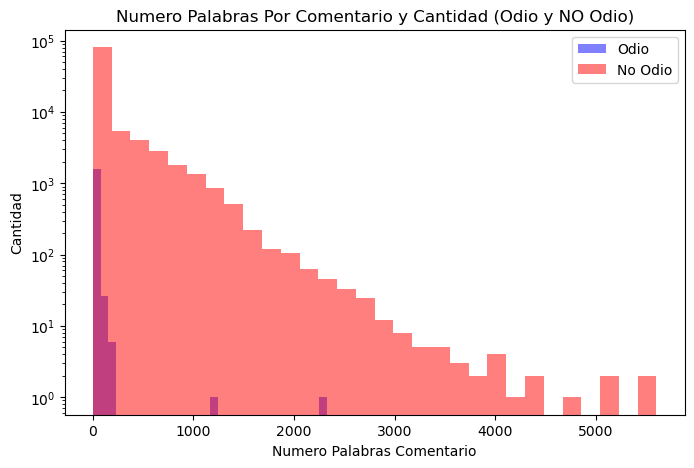

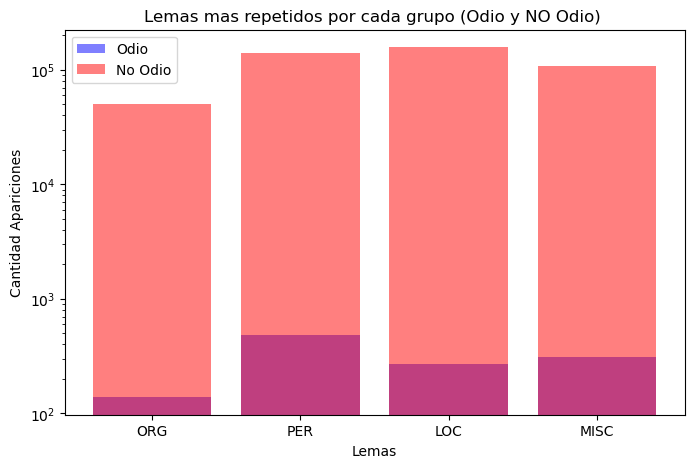


Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.98      1.00      0.99     19683
           1       0.00      0.00      0.00       314

    accuracy                           0.98     19997
   macro avg       0.49      0.50      0.50     19997
weighted avg       0.97      0.98      0.98     19997


El modelo predice en un  98.43 %


C:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
C:\Users\User\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


<Figure size 800x500 with 0 Axes>

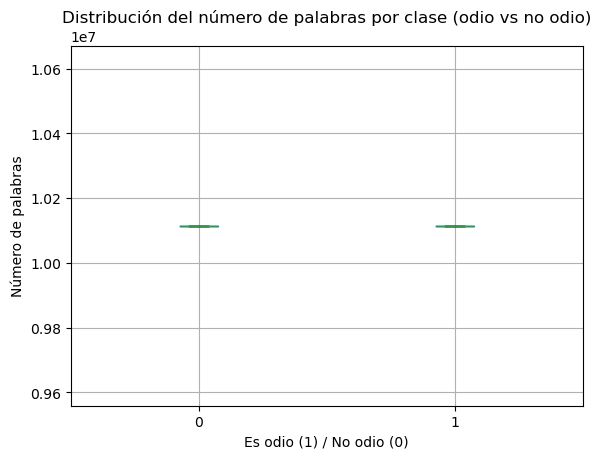


 El tiempo que se demoró el proceso fue:  92.0 minutos


In [7]:
# Incluye aquí el código generado para poder responder a tu pregunta
start_11 = time.time() # variable guarda tiempo actual (inicio)
palabras_odio_11 = [] # lista para gaurdar todas las palabras de odio
palabras_no_odio_11 = [] # lista para gaurdar todas las palabras de NO odio
contador_odio_11 = Counter() # se crea el contador de cada una de las entidades para el grupo de Odio
contador_no_odio_11 = Counter() # se crea el contador de cada una de las entidades para el grupo de NO Odio

for i in range(len(data)): # un for que recorre la cantidad de registros que tiene la variable data
    if data["INTENSIDAD"][i] > 0: # if que valida si el comentario es de odio (Si la intensidad es mayor a 0, es decir es considerado odio)
        oracion_odio_11 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'oracion_odio_11' se guarda la frase(comentario)
        for token_odio_11 in oracion_odio_11.ents: # for que recorre la entidad de cada una de las palabras de odio
            contador_odio_11[token_odio_11.label_] += 1 # se agrega la entidad al contador el lema de la palabra
        num_palabras_odio_11 = len(oracion_odio_11) # se saca la longitud de palabras y se guardan en la lista de palabras de Odio
        palabras_odio_11.append(num_palabras_odio_11) # se agrega el número de palabras a la lista palabras_odio_11
    elif data["INTENSIDAD"][i] == 0: # if que valida si el comentario es de odio (Si la intensidad es mayor a 0, es decir es considerado odio)
        oracion_no_odio_11 = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'oracion_odio_11' se guarda la frase(comentario)
        for token_no_odio_11 in oracion_no_odio_11.ents: # for que recorre la entidad de cada una de las palabras de odio
            contador_no_odio_11[token_no_odio_11.label_] += 1 # se agrega la entidad al contador el lema de la palabra
        num_palabras_no_odio_11 = len(oracion_no_odio_11) # se saca la longitud de palabras y se guardan en la lista de palabras de NO Odio
        palabras_no_odio_11.append(num_palabras_no_odio_11) # se agrega el número de palabras a la lista palabras_no_odio_11

# Histograma el cual muestra el número de palabras por cada uno de los grupos por la cantidad de veces que aparece.
plt.figure(figsize=(8, 5))
plt.hist(palabras_odio_11, bins=30, alpha=0.5,color='blue', label='Odio')
plt.hist(palabras_no_odio_11, bins=30, alpha=0.5,color='red', label='No Odio')
plt.xlabel('Numero Palabras Comentario')
plt.ylabel('Cantidad')
plt.yscale('log')
plt.title('Numero Palabras Por Comentario y Cantidad (Odio y NO Odio)')
plt.legend()
plt.show()

# Gráfica de barras que muestra los lemas más repetidos de cada grupo
lema_odio_11 = list(contador_odio_11.keys())
lema_no_odio_11 = list(contador_no_odio_11.keys())
cantidad_odio_11 = list(contador_odio_11.values())
cantidad_no_odio_11 = list(contador_no_odio_11.values())
plt.figure(figsize=(8, 5))
plt.bar(lema_odio_11[:10], cantidad_odio_11[:10], color='blue', alpha=0.5, label='Odio')
plt.bar(lema_no_odio_11[:10], cantidad_no_odio_11[:10], color='red' , alpha=0.5, label='No Odio')
plt.yscale('log')
plt.title('Lemas mas repetidos por cada grupo (Odio y NO Odio) ')
plt.xlabel('Lemas')
plt.ylabel('Cantidad Apariciones')
plt.legend()
plt.show()


#MODELO DE PREDICCIÓN
#Librería de python 'sklearn', para ML, entrenamiento de modelos.
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score

num_pal_lista_11 = [] # Lista para guardar el número de palabras (tokens válidos) por comentario
es_odio_11 = [] # lista que defino si un comentario es de Odio(1) o NO Odio(0)

# Se desea agregar una columna nueva llamada 'NUM_PALABRAS' con el número total de palabras del comentario
for i in range(len(data)): # un for para recorrer cada registro de el dataframe 'data'
    comentario_odio_11_ = nlp(data["CONTENIDO A ANALIZAR"][i]) # en la varible 'oracion_odio_11_' se guardan las caracteristicas de la frase(comentario)
    for token in comentario_odio_11_: # un for que recorre cada una de las palabras del comentario (odio)
        if token.is_alpha: # if que valida si la palabra es alfabética
            num_pal_lista_11.append(token) # si es alfabética se agrega a la lista 'num_pal_lista_11'

data['NUM_PALABRAS'] = len(num_pal_lista_11) # se agrega la nueva columna NUM_PALABRAS al DataFrame

# Se desea agregar una columna nueva llamada 'ES_ODIO' con el número '1' si es ODIO y '0' NO ODIO
for i in range(len(data)): # n for para recorrer cada registro de el dataframe 'data'
    if data["INTENSIDAD"][i] > 0: # if que valida si el comentario es de odio (Si la intensidad es mayor a 0, es decir es considerado odio)
        es_odio_11.append(1) # se agrega '1' si es considerado ODIO
    else:
        es_odio_11.append(0) # se agrega '0' si es considerado NO ODIO

data['ES_ODIO'] = es_odio_11 # se agrega la nueva columna ES_ODIO al DataFrame

X = data[['NUM_PALABRAS']] # se asigna al label X el atributo NUM_PALABRAS
y = data['ES_ODIO'] # se asigna al label Y el atributo ES_ODIO
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) # se divide el dataset (80% entrenamiento, 20% prueba)
modelo = LogisticRegression() # se usd un modelo de regresión logística 'LogisticRegression'
modelo.fit(X_train, y_train) # Se entrena el modelo con los datos de entrenamiento
y_pred = modelo.predict(X_test) # Se predicen con los datos de prueba
precision_modelo = accuracy_score(y_test, y_pred) # se asigna a la variable la precision del modelo

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred)) # se imprime el reporte de clasificación con los datos de entrenamiento y predicción

print("\nEl modelo predice en un " , round((precision_modelo*100), 2) , "%") # se imprime el procentaje en el que predice el modelo

# GRAFICA DE DISTRIBUCIÓN
plt.figure(figsize=(8, 5)) 
data.boxplot(column='NUM_PALABRAS', by='ES_ODIO')
plt.title("Distribución del número de palabras por clase (odio vs no odio)")
plt.suptitle("")
plt.xlabel("Es odio (1) / No odio (0)")
plt.ylabel("Número de palabras")
plt.show()

end_11 = time.time() # variable guarda tiempo final
print("\n El tiempo que se demoró el proceso fue: " , round((end_11-start_11)/60, 0) , "minutos") # se imprime los segundos que toma el proceso